## 1 Stock Selection and Data collection

This project analyses 10 U.S.-listed companies selected from a range of sectors and industries:

- Apple (AAPL) — Technology
- NVIDIA (NVDA) — Semiconductors / Technology
- JPMorgan Chase (JPM) — Financials
- Exxon Mobil (XOM) — Energy
- Coca-Cola (KO) — Consumer Staples
- Walmart (WMT) — Consumer Staples
- Eli Lilly (LLY) — Healthcare
- Caterpillar (CAT) — Industrials
- NextEra Energy (NEE) — Utilities
- Disney (DIS) — Communication Services / Entertainment

The S&P 500 Index (^GSPC) is used as the market benchmark.

The analysis period is January 2018 to December 2025. Price data will also be collected for December 2017 so that returns can be calculated from January 2018. The analysis will include return observations from January 2018 to December 2025.

## 1.1 Import Libraries

In [391]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm

## 1.2 Stock Selection

In [392]:
stock_tickers = [
    "AAPL", "NVDA", "JPM", "XOM", "KO",
    "WMT", "LLY", "CAT", "NEE", "DIS"
]

market_ticker = "^GSPC"
tickers = stock_tickers + [market_ticker]

print(f"Number of stocks: {len(stock_tickers)}")
print(f"Market benchmark: {market_ticker}")

Number of stocks: 10
Market benchmark: ^GSPC


## 1.3 Download Historical Price Data

In [393]:
download_start = "2017-12-01"
download_end = "2026-01-01" 

prices_raw = yf.download(
    tickers=tickers,
    start=download_start,
    end=download_end,
    interval="1d",
    auto_adjust=True,
    group_by="column",
    progress=True
)

if prices_raw is None or prices_raw.empty:
    raise RuntimeError(
        "No data were returned. Check your internet connection and try again."
    )

[*********************100%***********************]  11 of 11 completed


## 1.4 Extract Adjusted Closing Prices

In [394]:
prices = prices_raw["Close"].copy()

prices = prices.rename(columns={"^GSPC": "SP500"})

prices = prices.loc["2017-12-01":"2025-12-31"]

prices.head()

Ticker,AAPL,CAT,DIS,JPM,KO,LLY,NEE,NVDA,WMT,XOM,SP500
Date,,,,,,,,,,,
2017-12-01,39.949776,118.099289,98.448784,82.600655,35.145214,75.355843,31.577492,4.875834,28.221350,56.743706,2642.219971
2017-12-04,39.657833,118.082558,103.097626,84.303253,35.343998,75.585510,31.276682,4.604024,28.122786,56.818508,2639.439941
2017-12-05,39.620457,116.947632,100.291496,83.333725,35.366928,76.009430,31.210514,4.630663,28.360504,56.356178,2629.570068
2017-12-06,39.473320,117.114540,98.645218,82.711014,35.512196,75.355843,31.639639,4.668155,28.201059,55.941452,2629.270020
2017-12-07,39.545719,119.242538,98.458145,82.466660,34.999950,75.841637,31.719866,4.735490,28.203976,56.125038,2636.979980


## 1.5 Data Validation

In [395]:
expected_columns = stock_tickers + ["SP500"]
missing_tickers = [
    ticker for ticker in expected_columns
    if ticker not in prices.columns
]

print("Price data shape (rows, columns):", prices.shape)
print("Date range:", prices.index.min().date(), "to", prices.index.max().date())
print("Duplicate dates:", prices.index.duplicated().sum())
print("Missing ticker columns:", missing_tickers)

display(prices.tail())
display(
    prices.isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)

Price data shape (rows, columns): (2031, 11)
Date range: 2017-12-01 to 2025-12-31
Duplicate dates: 0
Missing ticker columns: []


Ticker,AAPL,CAT,DIS,JPM,KO,LLY,NEE,NVDA,WMT,XOM,SP500
Date,,,,,,,,,,,
2025-12-24,273.066711,580.214355,113.609474,322.950073,68.774155,1071.802002,78.732094,188.169678,110.903748,116.875404,6932.049805
2025-12-26,272.657837,579.458984,112.696465,321.713867,68.538734,1072.568237,78.692955,190.085190,111.032936,116.767570,6929.939941
2025-12-29,273.016876,575.095581,113.321678,317.632477,68.823212,1073.543579,78.555931,187.780594,111.817924,118.159645,6905.740234
2025-12-30,272.338684,573.882996,113.917114,317.308746,68.734924,1074.558716,78.810387,187.102173,111.211784,118.610596,6896.240234
2025-12-31,271.122009,569.390503,112.904869,316.131409,68.577972,1069.513062,78.565720,186.064621,110.705025,117.973381,6845.500000


,missing_values
Ticker,
AAPL,0
CAT,0
DIS,0
JPM,0
KO,0
LLY,0
NEE,0
NVDA,0
WMT,0


# 2. Return Calculation

Stock prices cannot be used directly in the CAPM regression. Therefore, the adjusted closing prices are converted into returns.

The simple return for asset $i$ at time $t$ is calculated as:

$$
R_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1
$$

where:

- $R_{i,t}$ is the return of asset $i$ at time $t$
- $P_{i,t}$ is the price of asset $i$ at time $t$
- $P_{i,t-1}$ is the price of the same asset in the previous period

## 2.1 Daily Returns

In [396]:
prices = prices.sort_index()
prices = prices.loc[~prices.index.duplicated(keep="first")]

daily_returns = prices.pct_change(fill_method=None)

daily_returns = daily_returns.loc["2018-01-01":"2025-12-31"]

daily_returns.head()

Ticker,AAPL,CAT,DIS,JPM,KO,LLY,NEE,NVDA,WMT,XOM,SP500
Date,,,,,,,,,,,
2018-01-02,0.017905,-0.003427,0.039903,0.009445,-0.007411,0.002605,-0.007043,0.030233,-0.001620,0.016619,0.008303
2018-01-03,-0.000174,0.001528,0.004293,0.001019,-0.002196,0.005432,-0.021213,0.065814,0.008723,0.019640,0.006399
2018-01-04,0.004645,0.013734,-0.000445,0.014326,0.014084,0.004463,-0.005139,0.005271,0.000905,0.001384,0.004029
2018-01-05,0.011385,0.015805,-0.005435,-0.006419,-0.000217,0.012278,0.004569,0.008474,0.005927,-0.000806,0.007034
2018-01-08,-0.003714,0.025130,-0.014334,0.001476,-0.001519,-0.005083,0.008239,0.030641,0.014781,0.004496,0.001662


## 2.2 Daily Return Validation

In [397]:
required_columns = stock_tickers + ["SP500"]

missing_columns = [
    column for column in required_columns
    if column not in daily_returns.columns
]
if missing_columns:
    raise ValueError(f"Missing return columns: {missing_columns}")

print("Shape:", daily_returns.shape)
print(
    "Date range:",
    daily_returns.index.min().date(),
    "to",
    daily_returns.index.max().date()
)

display(
    daily_returns.isna()
    .sum()
    .rename("missing_returns")
    .to_frame()
)

display(daily_returns.describe().T)

ticker_check = "AAPL"
date_check = daily_returns[ticker_check].first_valid_index()
position = prices.index.get_loc(date_check)
previous_date = prices.index[position - 1]

manual_return = (
    prices.loc[date_check, ticker_check]
    / prices.loc[previous_date, ticker_check]
    - 1
)

print("AAPL return from pct_change:", daily_returns.loc[date_check, ticker_check])
print("AAPL return calculated manually:", manual_return)

daily_returns_clean = daily_returns.dropna(subset=required_columns)

print("Complete daily return shape:", daily_returns_clean.shape)

Shape: (2011, 11)
Date range: 2018-01-02 to 2025-12-31


,missing_returns
Ticker,
AAPL,0
CAT,0
DIS,0
JPM,0
KO,0
LLY,0
NEE,0
NVDA,0
WMT,0


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,2011.0,0.001146,0.019395,-0.128647,-0.007916,0.001187,0.011073,0.153289
CAT,2011.0,0.000930,0.020026,-0.142822,-0.009325,0.000771,0.011846,0.116346
DIS,2011.0,0.000241,0.019421,-0.131632,-0.008631,0.000000,0.009147,0.144123
JPM,2011.0,0.000824,0.018290,-0.149649,-0.007638,0.000872,0.009375,0.180125
KO,2011.0,0.000408,0.012159,-0.096725,-0.005263,0.000642,0.006273,0.064796
LLY,2011.0,0.001518,0.019732,-0.141364,-0.007835,0.001662,0.010266,0.156798
NEE,2011.0,0.000604,0.017085,-0.134171,-0.007498,0.001099,0.009008,0.136904
NVDA,2011.0,0.002344,0.032308,-0.187558,-0.015095,0.002814,0.019821,0.243697
WMT,2011.0,0.000768,0.014002,-0.113757,-0.005765,0.000834,0.007487,0.117086


AAPL return from pct_change: 0.0179046485510701
AAPL return calculated manually: 0.0179046485510701
Complete daily return shape: (2011, 11)


## 2.3 Monthly return

In [398]:
monthly_prices = prices.resample("ME").last()

monthly_returns = monthly_prices.pct_change(fill_method=None)

monthly_returns = monthly_returns.loc["2018-01-31":"2025-12-31"]

monthly_returns.head()

Ticker,AAPL,CAT,DIS,JPM,KO,LLY,NEE,NVDA,WMT,XOM,SP500
Date,,,,,,,,,,,
2018-01-31,-0.010637,0.037794,0.010790,0.087269,0.037271,-0.035638,0.014278,0.270284,0.079494,0.043759,0.056179
2018-02-28,0.068185,-0.050067,-0.050704,-0.001470,-0.091826,-0.047352,-0.032708,-0.014848,-0.155629,-0.123545,-0.038947
2018-03-31,-0.058051,-0.046886,-0.026367,-0.047879,0.013729,0.004544,0.073481,-0.043017,-0.005661,-0.014919,-0.026884
2018-04-30,-0.015020,-0.015560,-0.001095,-0.005805,-0.005066,0.047822,0.003551,-0.028887,-0.005732,0.042086,0.002719
2018-05-31,0.135124,0.052300,-0.008572,-0.016272,-0.004860,0.056203,0.011592,0.122036,-0.061045,0.055479,0.021608


## 2.4 Monthly Return Validation

In [399]:
missing_columns = [
    column for column in required_columns
    if column not in monthly_returns.columns
]
if missing_columns:
    raise ValueError(f"Missing return columns: {missing_columns}")

print("Shape:", monthly_returns.shape)
print("Expected number of months:", 8 * 12)
print(
    "Date range:",
    monthly_returns.index.min().date(),
    "to",
    monthly_returns.index.max().date()
)

display(
    monthly_returns.isna()
    .sum()
    .rename("missing_monthly_returns")
    .to_frame()
)

display(monthly_returns.describe().T)

monthly_returns_clean = monthly_returns.dropna(subset=required_columns)

print("Complete monthly return shape:", monthly_returns_clean.shape)

Shape: (96, 11)
Expected number of months: 96
Date range: 2018-01-31 to 2025-12-31


,missing_monthly_returns
Ticker,
AAPL,0
CAT,0
DIS,0
JPM,0
KO,0
LLY,0
NEE,0
NVDA,0
WMT,0


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,96.0,0.023567,0.082373,-0.181197,-0.042266,0.026928,0.087403,0.216569
CAT,96.0,0.019410,0.091333,-0.199336,-0.047681,0.022810,0.071742,0.328062
DIS,96.0,0.005416,0.094705,-0.186133,-0.049661,-0.007350,0.054354,0.248734
JPM,96.0,0.016508,0.073077,-0.224614,-0.030844,0.019894,0.067280,0.215371
KO,96.0,0.008257,0.049827,-0.165488,-0.015235,0.014966,0.042209,0.128885
LLY,96.0,0.031626,0.085443,-0.177727,-0.023565,0.029482,0.093437,0.248232
NEE,96.0,0.011709,0.064792,-0.163239,-0.019200,0.013015,0.055249,0.194863
NVDA,96.0,0.048462,0.139671,-0.320274,-0.026921,0.054763,0.142377,0.363436
WMT,96.0,0.015659,0.055421,-0.156170,-0.016921,0.015978,0.051002,0.128737


Complete monthly return shape: (96, 11)


# 3. Risk-Free Rate

The CAPM requires a risk-free rate to calculate excess returns. In this project, the 3-month U.S. Treasury bill rate is used as a proxy for the risk-free rate.

The Treasury bill rate is obtained from the Federal Reserve Economic Data (FRED) database. Since the reported rate is annualised, it must be converted into daily and monthly rates to match the frequency of the stock and market returns.

## 3.1 Download Risk-Free Rate

In [400]:
fred_series = "DTB3"
fred_url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={fred_series}"

rf_raw = pd.read_csv(
    fred_url,
    index_col=0,
    parse_dates=True,
    na_values="."
)

rf_raw = rf_raw.rename(columns={fred_series: "rf_annual_pct"})
rf_raw["rf_annual_pct"] = pd.to_numeric(
    rf_raw["rf_annual_pct"],
    errors="coerce"
)

rf_raw = rf_raw.loc["2017-12-01":"2025-12-31"]
rf_raw = rf_raw.dropna(subset=["rf_annual_pct"]).sort_index()

display(rf_raw.head())
display(rf_raw.tail())

,rf_annual_pct
observation_date,
2017-12-01,1.25
2017-12-04,1.28
2017-12-05,1.28
2017-12-06,1.28
2017-12-07,1.27


,rf_annual_pct
observation_date,
2025-12-24,3.60
2025-12-26,3.56
2025-12-29,3.57
2025-12-30,3.55
2025-12-31,3.57


## 3.2 Prepare Daily Risk-Free Rate

In [401]:
rf_annual_daily = (
    rf_raw["rf_annual_pct"]
    .reindex(rf_raw.index.union(daily_returns.index))
    .sort_index()
    .ffill()
    .reindex(daily_returns.index)
)

daily_rf = (rf_annual_daily / 100 / 252).rename("RF")

## 3.3 Prepare Monthly Risk-Free Rate

In [402]:
monthly_rf = (
    (1 + daily_rf)
    .resample("ME")
    .prod()
    .sub(1)
    .rename("RF")
)

monthly_rf = monthly_rf.reindex(monthly_returns.index)

## 3.4 Risk-Free Rate Validation

In [403]:
print("Daily RF index matches daily returns:",
      daily_rf.index.equals(daily_returns.index))
print("Daily RF missing values:", daily_rf.isna().sum())
print("Daily RF min / max:", daily_rf.min(), "/", daily_rf.max())

print("Monthly RF index matches monthly returns:",
      monthly_rf.index.equals(monthly_returns.index))
print("Monthly RF missing values:", monthly_rf.isna().sum())
print("Monthly RF observations:", len(monthly_rf))

display(daily_rf.describe().to_frame("daily_RF"))
display(monthly_rf.describe().to_frame("monthly_RF"))

Daily RF index matches daily returns: True
Daily RF missing values: 0
Daily RF min / max: -1.984126984126984e-06 / 0.0002126984126984127
Monthly RF index matches monthly returns: True
Monthly RF missing values: 0
Monthly RF observations: 96


,daily_RF
count,2011.000000
mean,0.000102
std,0.000076
min,-0.000002
25%,0.000016
50%,0.000092
75%,0.000169
max,0.000213


,monthly_RF
count,96.000000
mean,0.002133
std,0.001606
min,0.000014
25%,0.000366
50%,0.001846
75%,0.003546
max,0.004845


# 4. Excess Returns

The CAPM is estimated using excess returns rather than raw returns. Excess return represents the return earned above the risk-free rate.

For each stock, the excess return is calculated as:

$$
R_{i,t}^{e} = R_{i,t} - R_{f,t}
$$

The market excess return is calculated as:

$$
R_{m,t}^{e} = R_{m,t} - R_{f,t}
$$

where:

- $R_{i,t}$ is the return of stock $i$ at time $t$
- $R_{m,t}$ is the market return at time $t$
- $R_{f,t}$ is the risk-free return at time $t$

Daily and monthly excess returns are constructed separately so that CAPM estimates can later be compared across the two frequencies.

## 4.1 Daily Excess Returns

In [404]:
daily_matched = daily_returns_clean.join(
    daily_rf.rename("RF"),
    how="inner"
)

daily_matched = daily_matched.dropna(
    subset=stock_tickers + ["SP500", "RF"]
)

daily_excess_returns = daily_matched[stock_tickers].sub(
    daily_matched["RF"],
    axis=0
)
daily_excess_returns = daily_excess_returns.add_suffix("_EXCESS")

daily_excess_returns["MKT_EXCESS"] = (
    daily_matched["SP500"] - daily_matched["RF"]
)

daily_excess_returns.head()

,AAPL_EXCESS,NVDA_EXCESS,JPM_EXCESS,XOM_EXCESS,KO_EXCESS,WMT_EXCESS,LLY_EXCESS,CAT_EXCESS,NEE_EXCESS,DIS_EXCESS,MKT_EXCESS
Date,,,,,,,,,,,
2018-01-02,0.017848,0.030177,0.009388,0.016563,-0.007467,-0.001676,0.002549,-0.003483,-0.007099,0.039847,0.008247
2018-01-03,-0.000229,0.065759,0.000964,0.019585,-0.002251,0.008668,0.005377,0.001473,-0.021269,0.004238,0.006344
2018-01-04,0.004590,0.005216,0.014271,0.001329,0.014029,0.000850,0.004408,0.013679,-0.005194,-0.000500,0.003973
2018-01-05,0.011331,0.008419,-0.006474,-0.000861,-0.000272,0.005872,0.012223,0.015751,0.004515,-0.005490,0.006979
2018-01-08,-0.003771,0.030584,0.001419,0.004439,-0.001576,0.014724,-0.005139,0.025073,0.008183,-0.014391,0.001606


## 4.2 Monthly Excess Returns

In [405]:
monthly_matched = monthly_returns_clean.join(
    monthly_rf.rename("RF"),
    how="inner"
)

monthly_matched = monthly_matched.dropna(
    subset=stock_tickers + ["SP500", "RF"]
)

monthly_excess_returns = monthly_matched[stock_tickers].sub(
    monthly_matched["RF"],
    axis=0
)
monthly_excess_returns = monthly_excess_returns.add_suffix("_EXCESS")

monthly_excess_returns["MKT_EXCESS"] = (
    monthly_matched["SP500"] - monthly_matched["RF"]
)

monthly_excess_returns.head()

,AAPL_EXCESS,NVDA_EXCESS,JPM_EXCESS,XOM_EXCESS,KO_EXCESS,WMT_EXCESS,LLY_EXCESS,CAT_EXCESS,NEE_EXCESS,DIS_EXCESS,MKT_EXCESS
Date,,,,,,,,,,,
2018-01-31,-0.011815,0.269106,0.086091,0.042581,0.036093,0.078315,-0.036817,0.036616,0.013099,0.009611,0.055000
2018-02-28,0.067003,-0.016030,-0.002653,-0.124728,-0.093009,-0.156811,-0.048534,-0.051250,-0.033890,-0.051887,-0.040130
2018-03-31,-0.059465,-0.044431,-0.049294,-0.016334,0.012314,-0.007076,0.003130,-0.048301,0.072066,-0.027782,-0.028299
2018-04-30,-0.016486,-0.030353,-0.007270,0.040620,-0.006531,-0.007198,0.046357,-0.017026,0.002085,-0.002561,0.001253
2018-05-31,0.133496,0.120408,-0.017900,0.053850,-0.006489,-0.062673,0.054574,0.050671,0.009963,-0.010200,0.019980


## 4.3 Excess Return Validation

In [406]:
def validate_excess_returns(data, matched_data, label):
    expected_columns = [
        f"{ticker}_EXCESS" for ticker in stock_tickers
    ] + ["MKT_EXCESS"]

    missing_columns = [
        column for column in expected_columns
        if column not in data.columns
    ]
    if missing_columns:
        raise ValueError(f"{label}: missing columns: {missing_columns}")

    if data.empty:
        raise ValueError(f"{label}: no excess-return observations")

    if not data.index.equals(matched_data.index):
        raise ValueError(f"{label}: dates do not match the aligned return data")

    print(f"{label} excess returns")
    print("Observations:", len(data))
    print("Date range:", data.index.min().date(), "to", data.index.max().date())
    print("Duplicate dates:", data.index.duplicated().sum())
    print("Missing values:", int(data[expected_columns].isna().sum().sum()))
    print(
        "All values finite:",
        np.isfinite(data[expected_columns].to_numpy()).all()
    )

    display(data.head())

validate_excess_returns(
    daily_excess_returns,
    daily_matched,
    "Daily"
)

validate_excess_returns(
    monthly_excess_returns,
    monthly_matched,
    "Monthly"
)

Daily excess returns
Observations: 2011
Date range: 2018-01-02 to 2025-12-31
Duplicate dates: 0
Missing values: 0
All values finite: True


,AAPL_EXCESS,NVDA_EXCESS,JPM_EXCESS,XOM_EXCESS,KO_EXCESS,WMT_EXCESS,LLY_EXCESS,CAT_EXCESS,NEE_EXCESS,DIS_EXCESS,MKT_EXCESS
Date,,,,,,,,,,,
2018-01-02,0.017848,0.030177,0.009388,0.016563,-0.007467,-0.001676,0.002549,-0.003483,-0.007099,0.039847,0.008247
2018-01-03,-0.000229,0.065759,0.000964,0.019585,-0.002251,0.008668,0.005377,0.001473,-0.021269,0.004238,0.006344
2018-01-04,0.004590,0.005216,0.014271,0.001329,0.014029,0.000850,0.004408,0.013679,-0.005194,-0.000500,0.003973
2018-01-05,0.011331,0.008419,-0.006474,-0.000861,-0.000272,0.005872,0.012223,0.015751,0.004515,-0.005490,0.006979
2018-01-08,-0.003771,0.030584,0.001419,0.004439,-0.001576,0.014724,-0.005139,0.025073,0.008183,-0.014391,0.001606


Monthly excess returns
Observations: 96
Date range: 2018-01-31 to 2025-12-31
Duplicate dates: 0
Missing values: 0
All values finite: True


,AAPL_EXCESS,NVDA_EXCESS,JPM_EXCESS,XOM_EXCESS,KO_EXCESS,WMT_EXCESS,LLY_EXCESS,CAT_EXCESS,NEE_EXCESS,DIS_EXCESS,MKT_EXCESS
Date,,,,,,,,,,,
2018-01-31,-0.011815,0.269106,0.086091,0.042581,0.036093,0.078315,-0.036817,0.036616,0.013099,0.009611,0.055000
2018-02-28,0.067003,-0.016030,-0.002653,-0.124728,-0.093009,-0.156811,-0.048534,-0.051250,-0.033890,-0.051887,-0.040130
2018-03-31,-0.059465,-0.044431,-0.049294,-0.016334,0.012314,-0.007076,0.003130,-0.048301,0.072066,-0.027782,-0.028299
2018-04-30,-0.016486,-0.030353,-0.007270,0.040620,-0.006531,-0.007198,0.046357,-0.017026,0.002085,-0.002561,0.001253
2018-05-31,0.133496,0.120408,-0.017900,0.053850,-0.006489,-0.062673,0.054574,0.050671,0.009963,-0.010200,0.019980


# 5. CAPM Regression

The Capital Asset Pricing Model (CAPM) is estimated using Ordinary Least Squares (OLS) regression for each of the 10 stocks.

The CAPM regression is specified as:

$$
R_{i,t} - R_{f,t}
=
\alpha_i
+
\beta_i(R_{m,t} - R_{f,t})
+
\epsilon_{i,t}
$$

where:

- $R_{i,t} - R_{f,t}$ is the stock excess return
- $R_{m,t} - R_{f,t}$ is the market excess return
- $\alpha_i$ is the intercept, representing the stock's abnormal excess return
- $\beta_i$ measures the stock's sensitivity to market excess returns
- $\epsilon_{i,t}$ is the residual

OLS regressions are estimated for each stock to obtain alpha, beta, R-squared, and p-values. Daily and monthly CAPM models are estimated separately, while comparisons between the two frequencies are presented in the results evaluation section.

## 5.1 CAPM Regression Functions

Two reusable functions are defined for the CAPM analysis.

The first function estimates an OLS CAPM regression for an individual stock using the stock's excess return as the dependent variable and the market excess return as the independent variable.

The second function summarises the fitted models and extracts the estimated alpha, beta, p-values, R-squared, and number of observations for each stock.

In [407]:
def run_capm_regression(excess_returns, ticker):
    stock_column = f"{ticker}_EXCESS"
    market_column = "MKT_EXCESS"

    required_columns = [stock_column, market_column]
    missing_columns = [
        column for column in required_columns
        if column not in excess_returns.columns
    ]

    if missing_columns:
        raise ValueError(f"Missing columns for {ticker}: {missing_columns}")

    # Remove missing or infinite observations for this regression
    model_data = (
        excess_returns[required_columns]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if model_data.empty:
        raise ValueError(f"No valid observations for {ticker}")

    y = model_data[stock_column]
    X = sm.add_constant(
        model_data[[market_column]],
        has_constant="add"
    )

    model = sm.OLS(y, X, missing="raise").fit()
    return model


def summarize_capm_results(models):
    rows = []

    for ticker, model in models.items():
        rows.append({
            "Ticker": ticker,
            "Alpha": model.params["const"],
            "Beta": model.params["MKT_EXCESS"],
            "Alpha p-value": model.pvalues["const"],
            "Beta p-value": model.pvalues["MKT_EXCESS"],
            "R-squared": model.rsquared,
            "Observations": int(model.nobs)
        })

    return (
        pd.DataFrame(rows)
        .set_index("Ticker")
        .sort_values("Beta", ascending=False)
    )

## 5.2 Daily CAPM Regression

The CAPM regression is estimated for each of the 10 stocks using daily excess returns.

The fitted models are stored for subsequent regression diagnostics and visualisation. A summary table reports the estimated alpha, beta, p-values, R-squared, and number of observations for each stock.

In [408]:
daily_capm_models = {}

for ticker in stock_tickers:
    daily_capm_models[ticker] = run_capm_regression(
        daily_excess_returns,
        ticker
    )

daily_capm_summary = summarize_capm_results(
    daily_capm_models
)

display(
    daily_capm_summary.style.format({
        "Alpha": "{:.6f}",
        "Beta": "{:.6f}",
        "Alpha p-value": "{:.3e}",
        "Beta p-value": "{:.3e}",
        "R-squared": "{:.6f}",
        "Observations": "{:.0f}"
    })
)

,Alpha,Beta,Alpha p-value,Beta p-value,R-squared,Observations
Ticker,,,,,,
NVDA,0.001436,1.822153,5.567e-03,1.247e-291,0.484790,2011
AAPL,0.000506,1.215962,6.504e-02,0.000e+00,0.598897,2011
JPM,0.000253,1.061588,3.743e-01,0.000e+00,0.513498,2011
CAT,0.000363,1.052257,2.865e-01,1.670e-240,0.420769,2011
DIS,-0.000307,1.009794,3.559e-01,6.231e-234,0.411983,2011
XOM,0.000085,0.805149,8.129e-01,8.067e-142,0.273892,2011
LLY,0.001121,0.666744,5.140e-03,1.711e-85,0.174004,2011
NEE,0.000208,0.665068,5.342e-01,1.100e-116,0.230893,2011
KO,0.000071,0.530367,7.548e-01,1.393e-151,0.289941,2011


## 1.5 Data Validation

## 5.3 Monthly CAPM Regression

The CAPM regression is estimated for each of the 10 stocks using monthly excess returns.

The fitted monthly models are stored for subsequent analysis and visualisation. A summary table reports the estimated alpha, beta, p-values, R-squared, and number of observations for each stock.

In [409]:
monthly_capm_models = {}

for ticker in stock_tickers:
    monthly_capm_models[ticker] = run_capm_regression(
        monthly_excess_returns,
        ticker
    )

monthly_capm_summary = summarize_capm_results(
    monthly_capm_models
)

display(
    monthly_capm_summary.style.format({
        "Alpha": "{:.6f}",
        "Beta": "{:.6f}",
        "Alpha p-value": "{:.3e}",
        "Beta p-value": "{:.3e}",
        "R-squared": "{:.6f}",
        "Observations": "{:.0f}"
    })
)

,Alpha,Beta,Alpha p-value,Beta p-value,R-squared,Observations
Ticker,,,,,,
NVDA,0.029962,1.852612,9.361e-03,5.367e-12,0.398552,96
DIS,-0.008516,1.335588,2.486e-01,7.959e-14,0.449425,96
CAT,0.006252,1.247989,3.898e-01,7.547e-13,0.422792,96
AAPL,0.011047,1.175685,8.452e-02,3.531e-14,0.458750,96
JPM,0.004316,1.138556,3.993e-01,4.866e-18,0.551184,96
XOM,0.001017,0.915779,8.958e-01,1.413e-07,0.256415,96
WMT,0.008698,0.546524,9.048e-02,1.312e-06,0.221430,96
KO,0.001718,0.498614,7.086e-01,1.008e-06,0.225638,96
NEE,0.005243,0.490383,4.089e-01,3.249e-04,0.129060,96


# 6. Results Evaluation and Interpretation

This section evaluates and interprets the CAPM results for the 10 selected stocks.

The analysis compares alpha, beta, R-squared, and statistical significance across stocks and examines the relationship between stock and market excess returns. Regression diagnostics are used to evaluate residual behaviour, while rolling beta is used to examine the stability of systematic risk over time.

Daily and monthly CAPM estimates are also compared to assess whether the conclusions are sensitive to return frequency.

## 6.1 CAPM Results Table

The estimated alpha, beta, R-squared, and p-values are presented for each of the 10 stocks.

The results are used to compare systematic risk across stocks, identify stocks with beta above or below one, and examine whether alpha and beta estimates are statistically significant.

In [410]:
display(
   daily_capm_summary.style.format({
        "Alpha": "{:.5f}",
        "Alpha p-value": "{:.3e}",
        "Beta": "{:.5f}",
        "Beta p-value": "{:.3e}",
        "R-squared": "{:.5f}",
        "Observations": "{:.0f}"
    })
)

display(
    monthly_capm_summary.style.format({
        "Alpha": "{:.5f}",
        "Alpha p-value": "{:.3e}",
        "Beta": "{:.5f}",
        "Beta p-value": "{:.3e}",
        "R-squared": "{:.5f}",
        "Observations": "{:.0f}"
    })
)

,Alpha,Beta,Alpha p-value,Beta p-value,R-squared,Observations
Ticker,,,,,,
NVDA,0.00144,1.82215,5.567e-03,1.247e-291,0.48479,2011
AAPL,0.00051,1.21596,6.504e-02,0.000e+00,0.59890,2011
JPM,0.00025,1.06159,3.743e-01,0.000e+00,0.51350,2011
CAT,0.00036,1.05226,2.865e-01,1.670e-240,0.42077,2011
DIS,-0.00031,1.00979,3.559e-01,6.231e-234,0.41198,2011
XOM,0.00009,0.80515,8.129e-01,8.067e-142,0.27389,2011
LLY,0.00112,0.66674,5.140e-03,1.711e-85,0.17400,2011
NEE,0.00021,0.66507,5.342e-01,1.100e-116,0.23089,2011
KO,0.00007,0.53037,7.548e-01,1.393e-151,0.28994,2011


,Alpha,Beta,Alpha p-value,Beta p-value,R-squared,Observations
Ticker,,,,,,
NVDA,0.02996,1.85261,9.361e-03,5.367e-12,0.39855,96
DIS,-0.00852,1.33559,2.486e-01,7.959e-14,0.44943,96
CAT,0.00625,1.24799,3.898e-01,7.547e-13,0.42279,96
AAPL,0.01105,1.17569,8.452e-02,3.531e-14,0.45875,96
JPM,0.00432,1.13856,3.993e-01,4.866e-18,0.55118,96
XOM,0.00102,0.91578,8.958e-01,1.413e-07,0.25642,96
WMT,0.00870,0.54652,9.048e-02,1.312e-06,0.22143,96
KO,0.00172,0.49861,7.086e-01,1.008e-06,0.22564,96
NEE,0.00524,0.49038,4.089e-01,3.249e-04,0.12906,96


## 6.2 Daily vs Monthly CAPM Comparison

Daily and monthly CAPM estimates are compared to examine whether the estimated alpha, beta, R-squared, and statistical significance are sensitive to the return frequency.

The comparison is used to assess whether using daily or monthly data leads to different conclusions about the stocks' exposure to market risk.

In [411]:
metrics = [
    "Alpha",
    "Beta",
    "R-squared",
    "Alpha p-value",
    "Beta p-value"
]

frequency_comparison = (
    daily_results_table[metrics]
    .add_suffix(" (daily)")
    .join(
        monthly_results_table[metrics]
        .add_suffix(" (monthly)")
    )
)

# Simple annualisation approximation for alpha
frequency_comparison["Alpha annualised approx (daily)"] = (
    daily_results_table["Alpha"] * 252
)

frequency_comparison["Alpha annualised approx (monthly)"] = (
    monthly_results_table["Alpha"] * 12
)

display(
    frequency_comparison.style.format({
        "Alpha (daily)": "{:.5f}",
        "Alpha (monthly)": "{:.5f}",
        "Beta (daily)": "{:.5f}",
        "Beta (monthly)": "{:.5f}",
        "R-squared (daily)": "{:.5f}",
        "R-squared (monthly)": "{:.5f}",
        "Alpha p-value (daily)": "{:.3e}",
        "Alpha p-value (monthly)": "{:.3e}",
        "Beta p-value (daily)": "{:.3e}",
        "Beta p-value (monthly)": "{:.3e}",
        "Alpha annualised approx (daily)": "{:.5f}",
        "Alpha annualised approx (monthly)": "{:.5f}"
    })
)

,Alpha (daily),Beta (daily),R-squared (daily),Alpha p-value (daily),Beta p-value (daily),Alpha (monthly),Beta (monthly),R-squared (monthly),Alpha p-value (monthly),Beta p-value (monthly),Alpha annualised approx (daily),Alpha annualised approx (monthly)
Ticker,,,,,,,,,,,,
AAPL,0.00051,1.21596,0.59890,6.504e-02,0.000e+00,0.01105,1.17569,0.45875,8.452e-02,3.531e-14,0.12755,0.13257
NVDA,0.00144,1.82215,0.48479,5.567e-03,1.247e-291,0.02996,1.85261,0.39855,9.361e-03,5.367e-12,0.36197,0.35954
JPM,0.00025,1.06159,0.51350,3.743e-01,0.000e+00,0.00432,1.13856,0.55118,3.993e-01,4.866e-18,0.06376,0.05180
XOM,0.00009,0.80515,0.27389,8.129e-01,8.067e-142,0.00102,0.91578,0.25642,8.958e-01,1.413e-07,0.02154,0.01220
KO,0.00007,0.53037,0.28994,7.548e-01,1.393e-151,0.00172,0.49861,0.22564,7.086e-01,1.008e-06,0.01800,0.02062
WMT,0.00044,0.50256,0.19638,1.130e-01,1.690e-97,0.00870,0.54652,0.22143,9.048e-02,1.312e-06,0.11191,0.10437
LLY,0.00112,0.66674,0.17400,5.140e-03,1.711e-85,0.02653,0.33540,0.03484,3.172e-03,6.864e-02,0.28254,0.31836
CAT,0.00036,1.05226,0.42077,2.865e-01,1.670e-240,0.00625,1.24799,0.42279,3.898e-01,7.547e-13,0.09139,0.07502
NEE,0.00021,0.66507,0.23089,5.342e-01,1.100e-116,0.00524,0.49038,0.12906,4.089e-01,3.249e-04,0.05239,0.06292


## 6.3 Scatter Plots and Regression Lines

Scatter plots are used to visualise the relationship between each stock's daily excess return and the market excess return.

Each point represents one daily observation. The market excess return is shown on the horizontal axis, while the stock excess return is shown on the vertical axis.

The fitted CAPM regression line is added to each plot. The slope of the regression line represents the estimated beta, while the intercept represents the estimated alpha.

A steeper regression line therefore indicates greater sensitivity of the stock's excess return to movements in the market excess return.

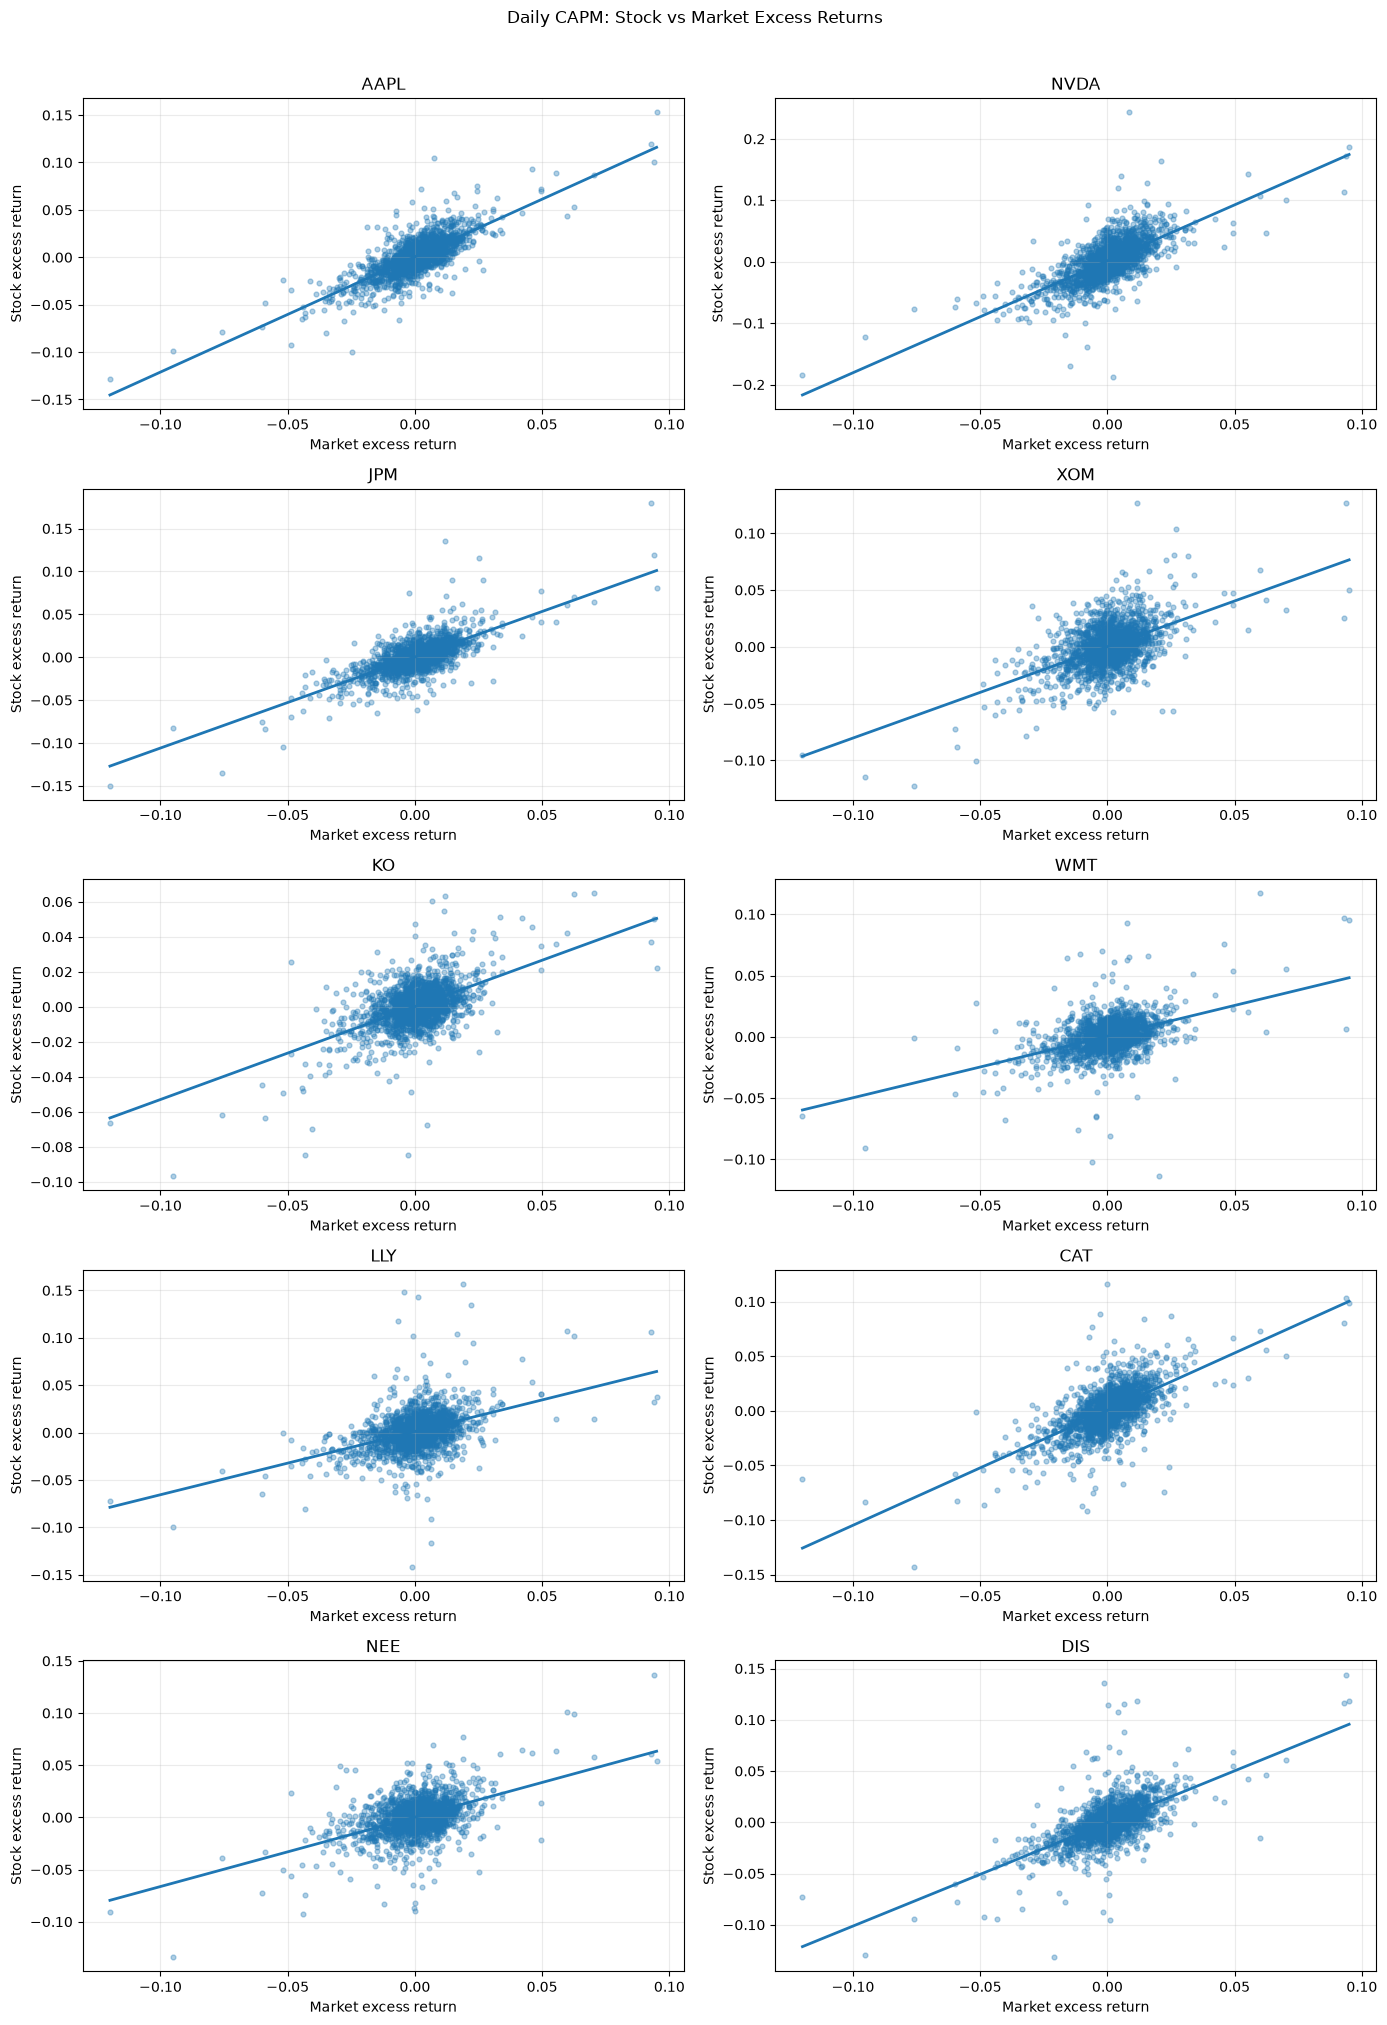

In [412]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for ax, ticker in zip(axes, stock_tickers):
    stock_column = f"{ticker}_EXCESS"
    model = daily_capm_models[ticker]

    plot_data = daily_excess_returns[
        [stock_column, "MKT_EXCESS"]
    ].dropna()

    x = plot_data["MKT_EXCESS"]
    y = plot_data[stock_column]

    ax.scatter(x, y, alpha=0.35, s=12)

    x_line = np.linspace(x.min(), x.max(), 100)

    y_line = (
        model.params["const"]
        + model.params["MKT_EXCESS"] * x_line
    )

    ax.plot(x_line, y_line, linewidth=2)

    ax.set_title(ticker)
    ax.set_xlabel("Market excess return")
    ax.set_ylabel("Stock excess return")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Daily CAPM: Stock vs Market Excess Returns",
    y=1.01
)

fig.tight_layout()

fig.savefig(
    "../output/regression_lines.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6.4 Residual Analysis

Residual plots are used to assess the behaviour of the errors from the daily CAPM regressions.

The fitted stock excess return is shown on the horizontal axis, while the regression residual is shown on the vertical axis. The residual is defined as the difference between the actual and fitted stock excess return.

A horizontal reference line at zero is included to make deviations from the fitted CAPM relationship easier to identify.

If the residuals are randomly distributed around zero without a clear systematic pattern, this provides support for the linear specification of the model. Visible patterns, changes in dispersion, or extreme residuals may indicate features of stock returns that are not fully captured by the CAPM.

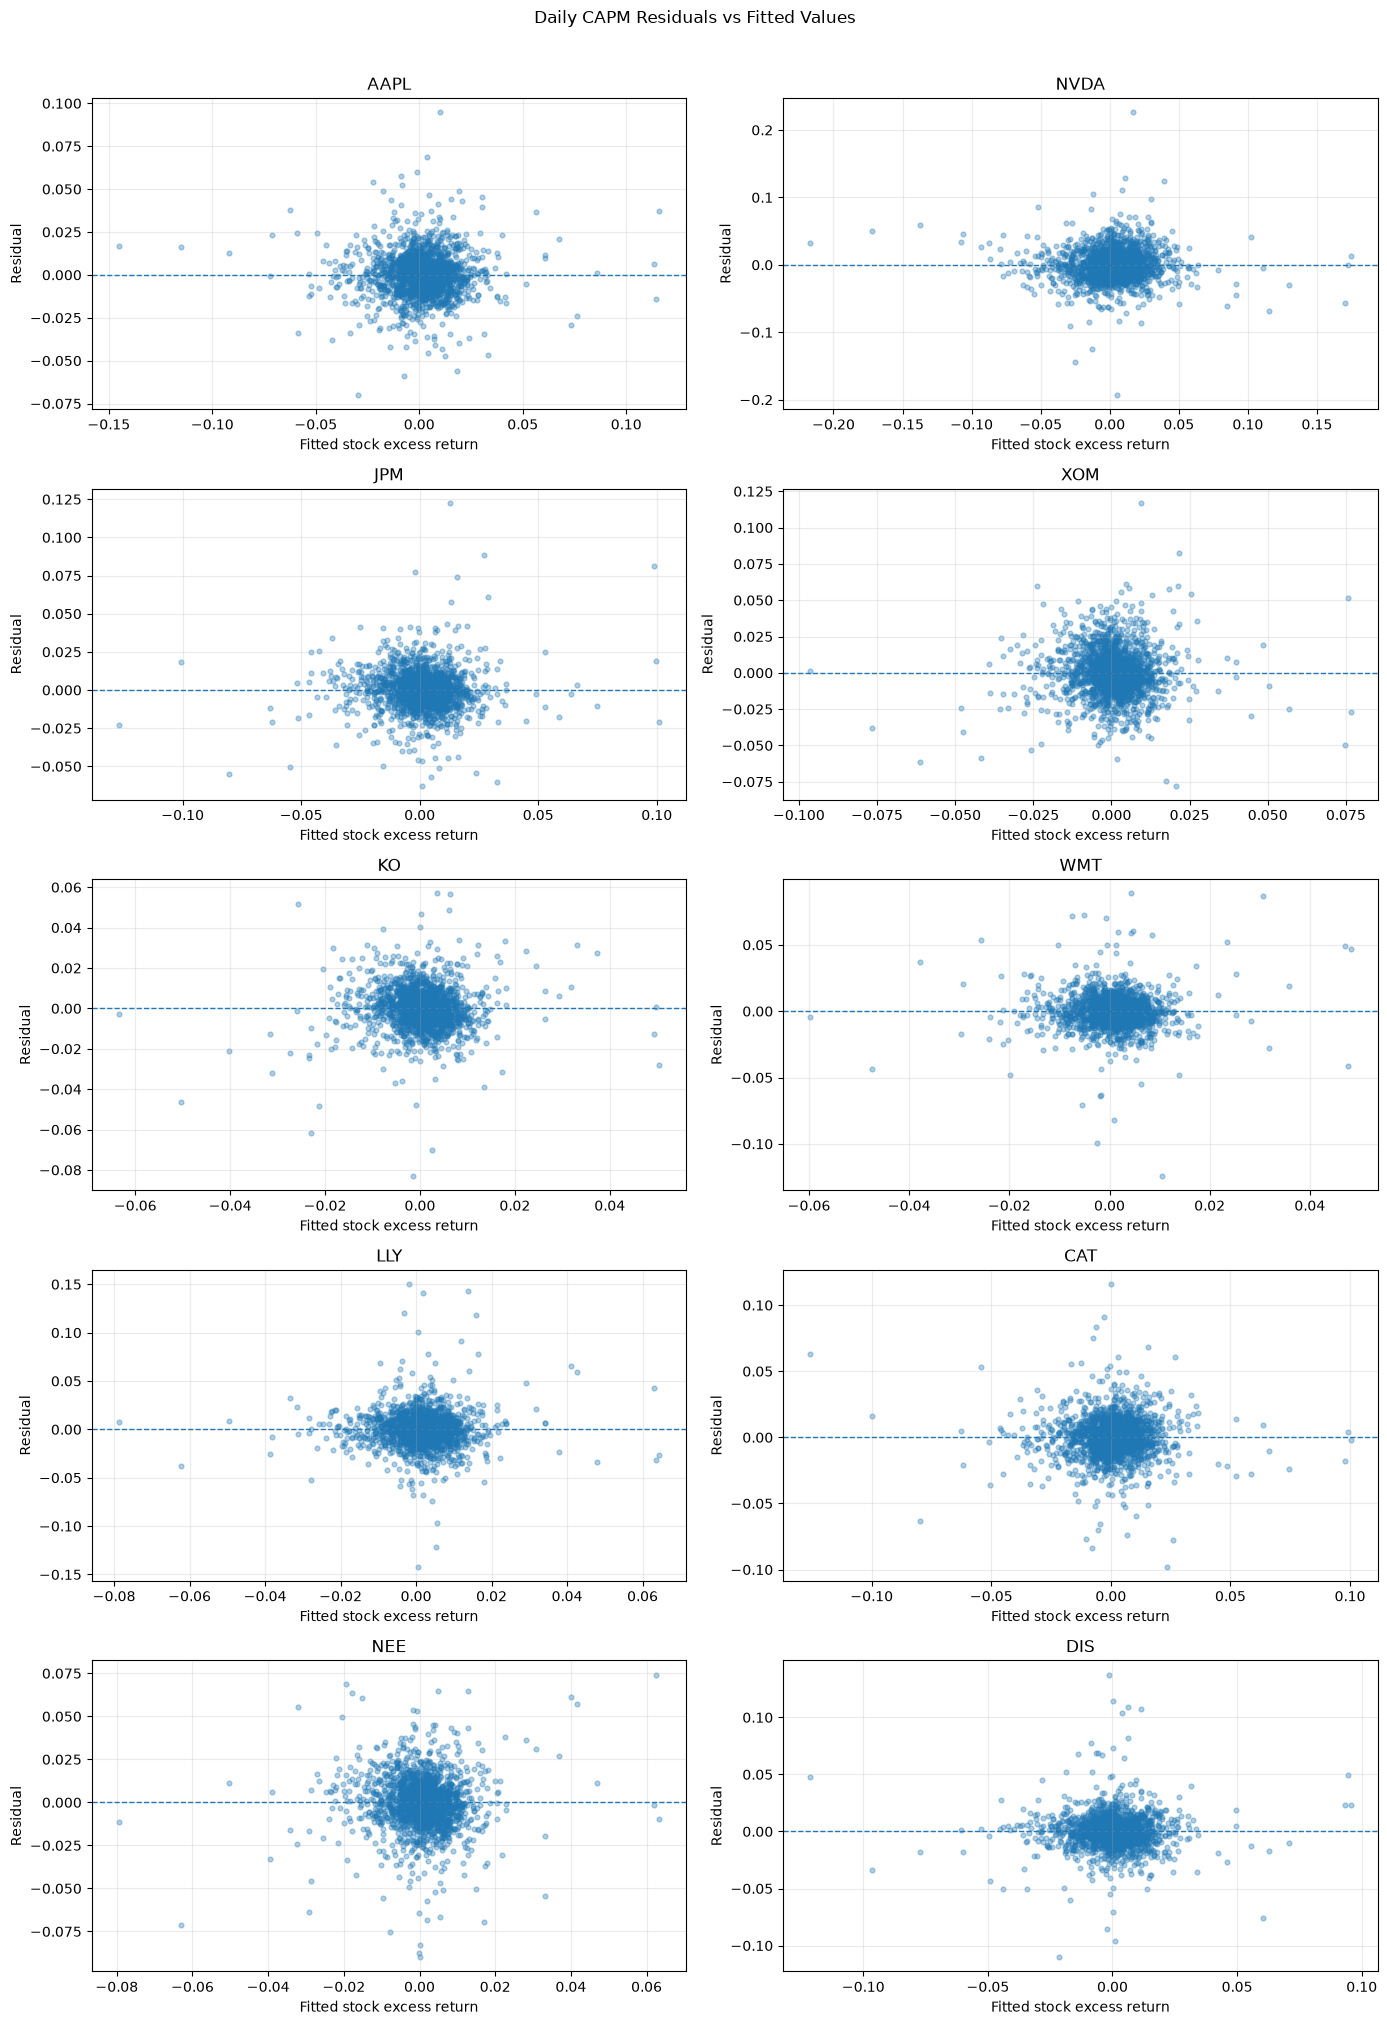

In [413]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for ax, ticker in zip(axes, stock_tickers):
    model = daily_capm_models[ticker]

    ax.scatter(
        model.fittedvalues,
        model.resid,
        alpha=0.35,
        s=12
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(ticker)
    ax.set_xlabel("Fitted stock excess return")
    ax.set_ylabel("Residual")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Daily CAPM Residuals vs Fitted Values",
    y=1.01
)

fig.tight_layout()

fig.savefig(
    "../output/residuals_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6.5 Beta Comparison Across Stocks

The estimated CAPM betas are compared across the 10 stocks using a bar chart.

Daily and monthly beta estimates are displayed side by side to show both cross-sectional differences across stocks and differences arising from return frequency.

A reference line at beta equal to one is included. Stocks with beta above one have greater estimated sensitivity to market excess returns, while stocks with beta below one have lower estimated market sensitivity.

The comparison is also used to examine whether relatively defensive stocks tend to have lower beta estimates than more market-sensitive stocks.

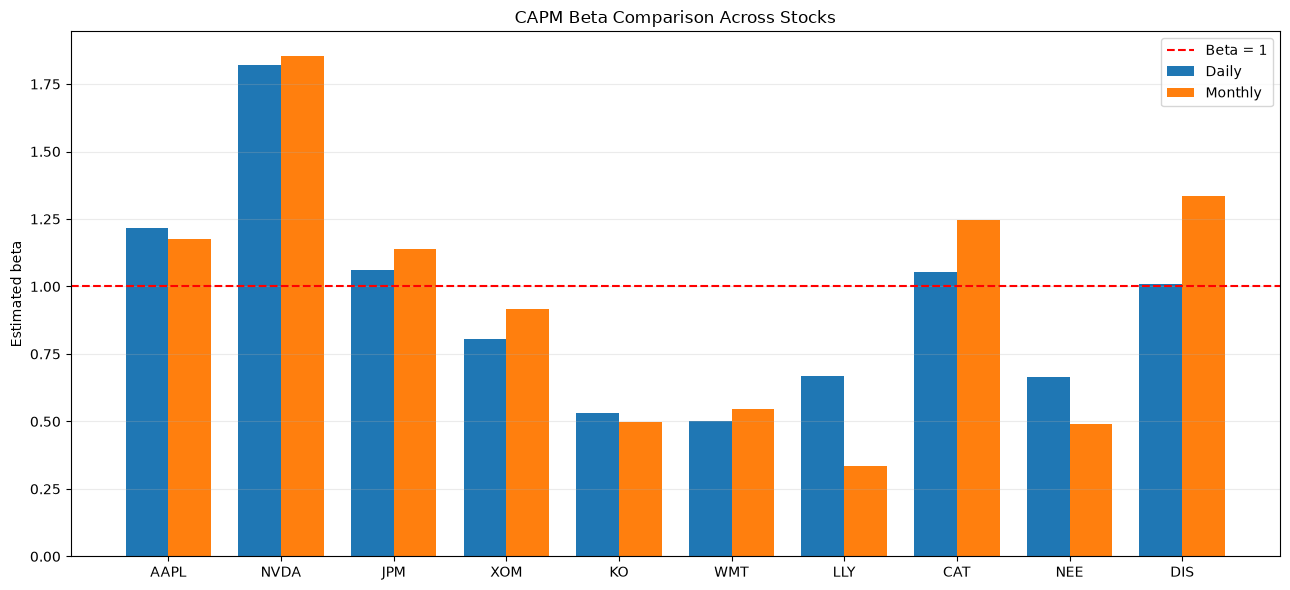

In [414]:
beta_data = pd.DataFrame({
    "Daily": daily_results_table["Beta"],
    "Monthly": monthly_results_table["Beta"]
}).reindex(stock_tickers)

x = np.arange(len(stock_tickers))
width = 0.38

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - width / 2, beta_data["Daily"], width, label="Daily")
ax.bar(x + width / 2, beta_data["Monthly"], width, label="Monthly")
ax.axhline(1, color="red", linestyle="--", label="Beta = 1")

ax.set_xticks(x)
ax.set_xticklabels(stock_tickers)
ax.set_ylabel("Estimated beta")
ax.set_title("CAPM Beta Comparison Across Stocks")
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    "../output/beta_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6.6 Rolling Beta and Stability Over Time

A 252-trading-day rolling window is used to examine whether the estimated market beta of each stock remains stable over time. A 252-day window approximately represents one trading year.

For each rolling window, beta is calculated as:

$$
\beta_{i,t}
=
\frac{
\operatorname{Cov}(R_i-R_f,\ R_m-R_f)
}{
\operatorname{Var}(R_m-R_f)
}
$$

The rolling beta series allows changes in market sensitivity to be observed over time. A reference line at beta equal to one is included to distinguish periods of relatively high and low market sensitivity.

The results can also be used to examine whether beta changes during periods of market stress.

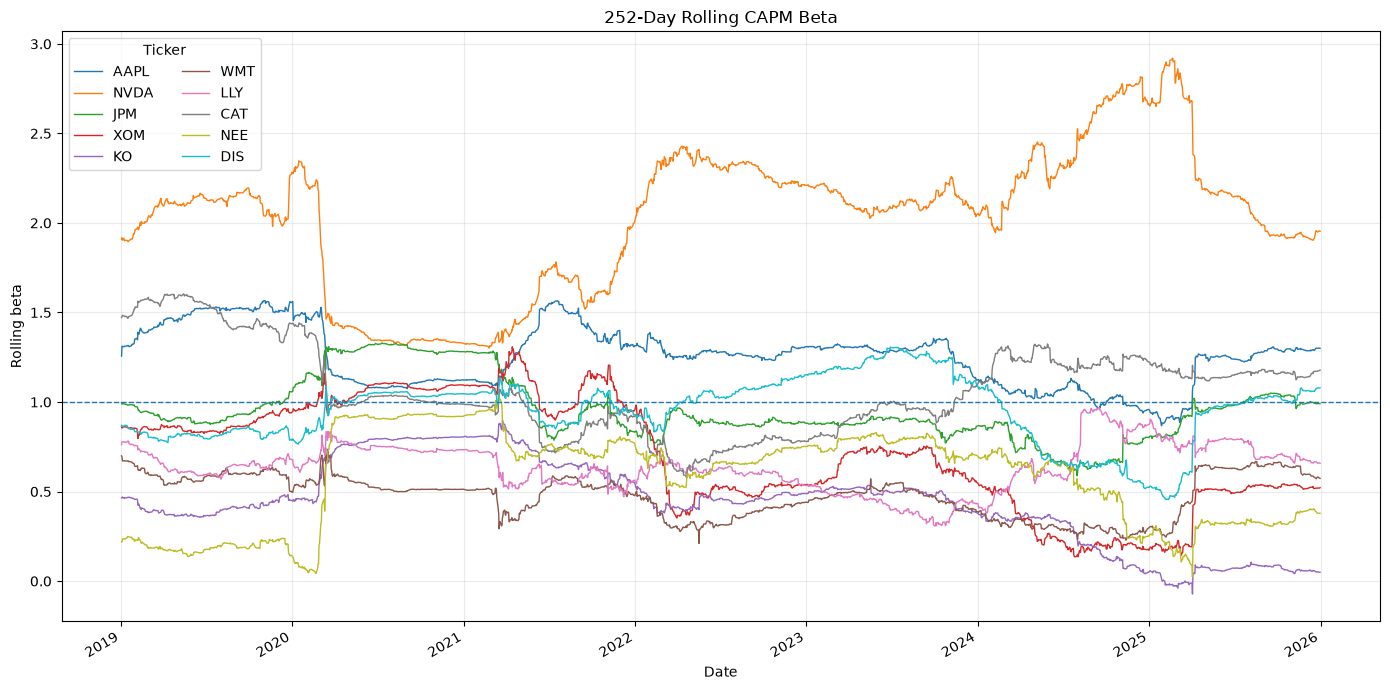

In [415]:
window = 252
market_excess = daily_excess_returns["MKT_EXCESS"]

rolling_betas = pd.DataFrame(
    index=daily_excess_returns.index
)

for ticker in stock_tickers:
    stock_excess = daily_excess_returns[
        f"{ticker}_EXCESS"
    ]

    rolling_covariance = stock_excess.rolling(
        window=window,
        min_periods=window
    ).cov(market_excess)

    rolling_market_variance = market_excess.rolling(
        window=window,
        min_periods=window
    ).var()

    rolling_betas[ticker] = (
        rolling_covariance
        / rolling_market_variance
    )

ax = rolling_betas.plot(
    figsize=(14, 7),
    linewidth=1
)

ax.axhline(
    1,
    linestyle="--",
    linewidth=1
)

ax.set_title("252-Day Rolling CAPM Beta")
ax.set_xlabel("Date")
ax.set_ylabel("Rolling beta")
ax.grid(alpha=0.25)
ax.legend(title="Ticker", ncol=2)

plt.tight_layout()

plt.savefig(
    "../output/rolling_beta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6.7 In-Sample Regression Summary

A detailed in-sample OLS regression summary is presented for Apple (AAPL) as a representative example.

Both the daily and monthly CAPM regression summaries are reported. The full regression output provides additional information on the estimated coefficients, statistical significance, model explanatory power, and regression diagnostics.

The summary complements the cross-sectional results tables presented earlier by providing a more detailed view of an individual CAPM regression.

In [416]:
ticker_to_review = "AAPL"

print(f"Daily CAPM summary: {ticker_to_review}")
display(daily_capm_models[ticker_to_review].summary())

print(f"Monthly CAPM summary: {ticker_to_review}")
display(monthly_capm_models[ticker_to_review].summary())

Daily CAPM summary: AAPL


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            AAPL_EXCESS   R-squared:                       0.599
Model:                            OLS   Adj. R-squared:                  0.599
Method:                 Least Squares   F-statistic:                     3000.
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:08:13   Log-Likelihood:                 5994.2
No. Observations:                2011   AIC:                        -1.198e+04
Df Residuals:                    2009   BIC:                        -1.197e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      1.846      0.065   -3.16e-05       0.001
MKT_EXCESS     1.2160      0.022     54.769      0.000       1.172       1.260
==============================================================================
Omnibus:                      273.423   Durbin-Watson:                   1.842
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2154.450
Skew:                           0.376   Prob(JB):                         0.00
Kurtosis:                       8.014   Cond. No.                         81.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Monthly CAPM summary: AAPL


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            AAPL_EXCESS   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.453
Method:                 Least Squares   F-statistic:                     79.67
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           3.53e-14
Time:                        17:08:13   Log-Likelihood:                 133.25
No. Observations:                  96   AIC:                            -262.5
Df Residuals:                      94   BIC:                            -257.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0110      0.006      1.743      0.085      -0.002       0.024
MKT_EXCESS     1.1757      0.132      8.926      0.000       0.914       1.437
==============================================================================
Omnibus:                        4.185   Durbin-Watson:                   1.785
Prob(Omnibus):                  0.123   Jarque-Bera (JB):                3.942
Skew:                          -0.281   Prob(JB):                        0.139
Kurtosis:                       3.818   Cond. No.                         21.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 6.8 Overall Findings

The CAPM results reveal substantial differences in systematic market risk across the 10 selected stocks.

NVDA has the highest estimated beta in both the daily and monthly models, with beta estimates of approximately 1.82 and 1.85, respectively. This indicates substantially greater sensitivity to market movements than the other stocks in the sample. AAPL also has a beta above one under both frequencies. JPM and CAT have beta estimates close to or above one, while their monthly estimates are somewhat higher than their daily estimates.

In contrast, KO and WMT have relatively low beta estimates of approximately 0.5 under both daily and monthly specifications. NEE also has a beta below one, while XOM remains below one in both specifications. These results are broadly consistent with the idea that some relatively defensive stocks have lower exposure to systematic market risk.

The explanatory power of the CAPM varies considerably across stocks. Using daily data, AAPL has the highest R-squared in the sample at approximately 0.60, followed by JPM, NVDA, CAT, and DIS. In contrast, LLY has a relatively low daily R-squared of approximately 0.17. Its monthly R-squared falls further to approximately 0.03, suggesting that market excess returns explain only a small proportion of LLY's monthly excess-return variation.

Most estimated alphas are not statistically significant at the 5% level. However, NVDA and LLY have statistically significant positive alpha estimates in both the daily and monthly regressions. The remaining stocks do not provide sufficient evidence of non-zero alpha at the 5% significance level.

The beta estimates are generally statistically significant, providing strong evidence of exposure to systematic market risk. The daily and monthly beta estimates lead to broadly similar conclusions for several stocks, although meaningful differences appear for some companies. For example, DIS has a daily beta close to one but a substantially higher monthly beta, while LLY has a considerably lower monthly beta than its daily estimate. This indicates that estimated market sensitivity can depend on the return frequency used.

The scatter plots show positive relationships between market excess returns and stock excess returns for all 10 stocks, although the strength and dispersion of these relationships vary across companies. The residual plots are generally centred around zero but contain several large observations and changes in dispersion, indicating that individual stock returns also contain substantial variation that is not captured by the single market factor.

The 252-day rolling beta analysis provides further evidence that beta is not constant over time. NVDA consistently exhibits relatively high market sensitivity and shows substantial variation in beta across the sample period. Several other stocks also experience noticeable changes in beta, particularly around periods of market disruption. Therefore, a single full-sample beta should be interpreted as an average exposure over the sample rather than as a permanently fixed measure of systematic risk.

Overall, the results support the main CAPM prediction that stocks differ substantially in their exposure to systematic market risk. However, the variation in R-squared, residual behaviour, differences between daily and monthly estimates, and changing rolling betas also show that the single-factor CAPM does not fully explain the behaviour of individual stock returns.

# 7. Conclusion

This project applied the Capital Asset Pricing Model (CAPM) to 10 U.S. stocks from different industries using data from 2018 to 2025. The analysis estimated each stock's alpha, beta, R-squared, and statistical significance using both daily and monthly excess returns.

The results show substantial differences in systematic market risk across the selected stocks. NVDA has the highest estimated beta under both daily and monthly specifications, indicating relatively high sensitivity to market movements. In contrast, stocks such as KO and WMT have substantially lower beta estimates. This provides some evidence that relatively defensive stocks tend to have lower exposure to systematic market risk.

The CAPM also has different explanatory power across stocks. For some companies, such as AAPL, market excess returns explain a relatively large proportion of excess-return variation, while the explanatory power is considerably lower for other stocks such as LLY. This suggests that company-specific and industry-specific factors remain important in explaining individual stock returns.

Most estimated alphas are not statistically significant at the 5% level, although NVDA and LLY show statistically significant positive alpha estimates in both the daily and monthly regressions. The beta estimates are generally statistically significant, providing strong evidence that the selected stocks are exposed to systematic market risk.

Comparing daily and monthly estimates shows that the overall conclusions are broadly similar, but the magnitude of beta and R-squared can change with return frequency. The rolling beta analysis also shows that beta is not constant over time. Therefore, a single CAPM beta should be interpreted as an average estimate for a particular sample period rather than a permanently fixed measure of risk.

Overall, the CAPM provides a useful and interpretable framework for measuring systematic market risk, but it does not fully explain individual stock returns. The results highlight both the usefulness and the limitations of a single-factor model and demonstrate the importance of considering return frequency, company-specific factors, and changes in market exposure over time.

# 8. Export Results

The processed datasets and key figures are exported for reproducibility and use in the project repository.

In [417]:
# Export processed datasets

prices.to_csv("../data/prices.csv")

daily_returns_clean.to_csv(
    "../data/daily_returns.csv"
)

monthly_returns_clean.to_csv(
    "../data/monthly_returns.csv"
)

daily_excess_returns.to_csv(
    "../data/daily_excess_returns.csv"
)

monthly_excess_returns.to_csv(
    "../data/monthly_excess_returns.csv"
)

print("Data exported successfully.")

Data exported successfully.
